# Programa3.Ejercicio Practico

**Noviembre 06, 2026**

![Descripción de la imagen](img/ITQ.png)

# 3. Ejercicio Practico


**Nombre:** Dilan Alvarez

**Fecha:** 06-11-2026

**Link Repositorio:** [Mi repositorio](https://github.com/da8846835-cyber/Normalizacion_ML)

2 Práctica Académica
2.1 Normalización y Estandarización de Datos en Inteligencia Artificial
3 Análisis y aplicación de técnicas de normalización y estandarización en conjunto de datos para modelos de aprendizaje
automático
3.0.1 Objetivo General
Aplicar Técnicas de normalización y estandarización de datos mediante herramientas de python, con
el fin de comprender su impacto en la prepación de datos y en el desempeño de modelos de aprendizaje automático. ### Objetivos especificos * Identificar diferencias de escala entre variables
numércias. * Aplicar técnicas de normalización (Min-Max) * Aplicar técnicas de estandarización
(Z-score) * Analizar la importancia del preprocesaminto en modelos de IA ### Antecedentes
/Fundamentación teórica En el contexto del aprendizaje automático, los algoritmos suelen verse
afectados por la escala de los datos. Variables con valores grandes pueden dominar el comportamiento del modelo, generando sesgos y resultados pocos conficables. Para mitigar este problema,
se emplea técnicas como: * Normalización: transforma los datos a un rango especifico (generalmente[0,1]) * Estandarización: ajusta los datos para que tengan media 0 y desviación estandar
1. Estas técnicas son fundamentales en algoritmos como: * KNN * Regresión logística * Redes
neuronales ### Escenario de práctica Una empresa de análisis de datos desea desarrollar modelos
predictivos utilizando información de clientes. Sin embargo, se ha identificado que las variables
1
presentan diferentes escalas, lo que puede afectar el rendimiento de los modelos. Se soliciata al
analista aplicar tecnicas de preprocesamiento y limpieza de datos para mejorar la calidad de lso
datos. ## Conjunto de datos utilizar Dataset 1(Conceptual): Iris dataset Dataset 2 (aplicación
real): California Housing Dataset

In [13]:
#Importacion de librerias
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris
import zipfile
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import preprocessing

In [14]:
 #Configuramos el entorno de descarga
import os
os.environ['KAGGLE_CONFIG_DIR']="C:/Users/USER-PC/.kaggle"

In [15]:
#Creamos la carpeta dataset
os.makedirs("dataset", exist_ok=True)

In [16]:
#Descargamos el dataset
!kaggle datasets download -d uciml/iris

Dataset URL: https://www.kaggle.com/datasets/uciml/iris
License(s): CC0-1.0
iris.zip: Skipping, found more recently modified local copy (use --force to force download)


In [18]:
#Descompriminos el archivo
with zipfile.ZipFile("iris.zip", 'r') as zip_ref:
    zip_ref.extractall("dataset")

In [19]:
 #Cargamos el conjunto de datos
df = pd.read_csv("dataset/Iris.csv")

In [29]:
# Eliminamos columnas innecesarias en la limpieza de datos. Como vemos en el
# dataframe, la columna id no aporta nada a nuestro modelo, por lo tanto la eliminamos
if 'Id' in df.columns:
    df = df.drop(columns=["Id"])

In [21]:
#Mostramos los detalles de nuesto dataset
df.info()
#Vrificamos si tenemos datos nulos si lo tenemos lo sumamos
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

In [22]:
#Separamos los datos de entrada con nuestra variable objetivo
X=df.drop(columns=['Species'])
y=df['Species']

In [23]:
#Exploramos o generamos un analis exploratorio del conjutno de datos
X.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


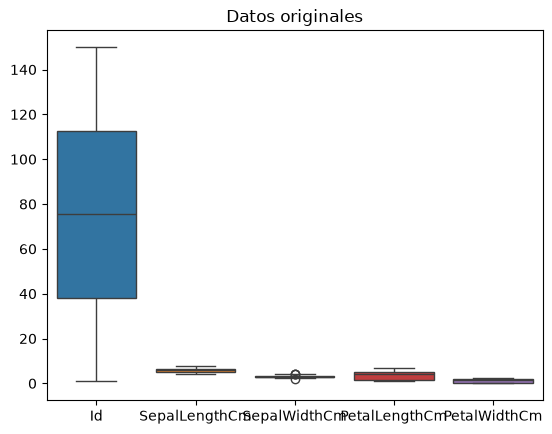

In [24]:
 #dibujamso los datos originales
sns.boxplot(data=X)
#Ponemos un titulo a la imagen
plt.title("Datos originales")
plt.show()

In [25]:
#Normalizamos el conjunto de datos
normalizer = preprocessing.MinMaxScaler()
X_norm=normalizer.fit_transform(X)
X_norm = pd.DataFrame(X_norm, columns=X.columns)
X_norm.head()


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,0.000000,0.222222,0.625000,0.067797,0.041667
1,0.006711,0.166667,0.416667,0.067797,0.041667
2,0.013423,0.111111,0.500000,0.050847,0.041667
3,0.020134,0.083333,0.458333,0.084746,0.041667
4,0.026846,0.194444,0.666667,0.067797,0.041667


In [26]:
 #Estaddarización
standarizer = preprocessing.StandardScaler()
#Estandarizamos los datos
X_std=standarizer.fit_transform(X)
X_std= pd.DataFrame(X_std, columns=X.columns)
X_std.head()


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,-1.720542,-0.900681,1.032057,-1.341272,-1.312977
1,-1.697448,-1.143017,-0.124958,-1.341272,-1.312977
2,-1.674353,-1.385353,0.337848,-1.398138,-1.312977
3,-1.651258,-1.506521,0.106445,-1.284407,-1.312977
4,-1.628164,-1.021849,1.263460,-1.341272,-1.312977


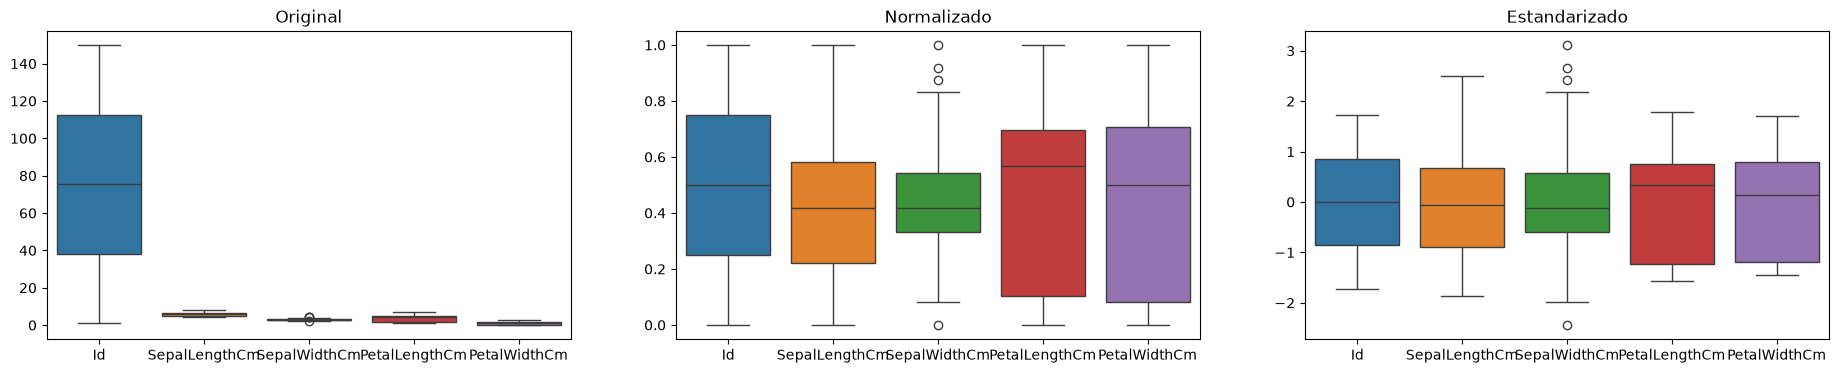

In [28]:
#Comporación visual
plt.figure(figsize=(23,4))
3
plt.subplot(1,3,1)
sns.boxplot(data=X)
plt.title("Original")
plt.subplot(1,3,2)
sns.boxplot(data=X_norm)
plt.title("Normalizado")
plt.subplot(1,3,3)
sns.boxplot(data=X_std)
plt.title("Estandarizado")
plt.show()
